# Διάγραμμα Voronoi και Τριγωνοποίηση Delaunay.


### Βοηθητικές βιβλιοθήκες για την υλοποίηση και παρουσίαση των αλγορίθμων

In [4]:
# third-party libraries
import numpy as np
import matplotlib.pyplot as plt
from scipy.spatial import Voronoi, voronoi_plot_2d, Delaunay, delaunay_plot_2d

### 1. Απεικόνιση της Αντιστοιχίας μεταξύ Τριγωνοποίηση Delaunay και Διαγράμματος Voronoi

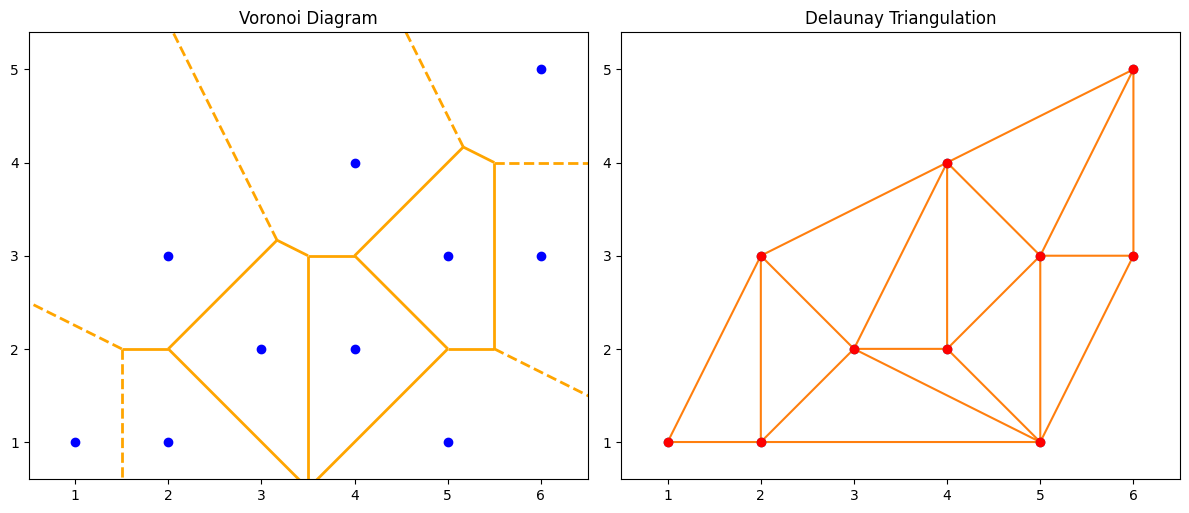

In [5]:
# set of points to work with
points = np.array([
    [1, 1],
    [2, 1],
    [2, 3],
    [3, 2],
    [4, 2],
    [4, 4],
    [5, 1],
    [5, 3],
    [6, 3],
    [6, 5]
])

# create voronoi diagram for given points
vor = Voronoi(points)

# create delaunay triangulation for given points
tri = Delaunay(points)

# figure with two subplots
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 6))

# --- Voronoi diagram ---
voronoi_plot_2d(vor, ax=ax1, show_vertices=False, line_colors='orange', line_width=2)
ax1.plot(points[:, 0], points[:, 1], 'bo') # blue points
ax1.set_title("Voronoi Diagram")
ax1.set_aspect('equal', adjustable='box')

# --- Delaunay triangulation ---
delaunay_plot_2d(tri, ax=ax2)
ax2.plot(points[:, 0], points[:, 1], 'ro') # red points
ax2.set_title("Delaunay Triangulation")
ax2.set_aspect('equal', adjustable='box')

# adjust spacing and show plots
plt.tight_layout()
plt.show()

### 2. Σχόλια για την πολυπλοκότητα των αλγορίθμων

Για τον υπολογισμό των δύο δομών χρησιμοποιούνται οι έτοιμες υλοποιήσεις της βιβλιοθήκης SciPy (`Voronoi` και `Delaunay`), οι οποίες βασίζονται στη βιβλιοθήκη Qhull.

**Διάγραμμα Voronoi**

Το διάγραμμα Voronoi χωρίζει το επίπεδο σε περιοχές, μία για κάθε σημείο του συνόλου, έτσι ώστε κάθε σημείο μιας περιοχής να βρίσκεται πιο κοντά στο σημείο της περιοχής του παρά σε οποιοδήποτε άλλο. Η `voronoi_plot_2d` σχεδιάζει τα όρια των περιοχών.

**Τριγωνοποίηση Delaunay**

Η τριγωνοποίηση Delaunay συνδέει τα σημεία με τρίγωνα, έτσι ώστε ο περιγεγραμμένος κύκλος κάθε τριγώνου να μην περιέχει κανένα άλλο σημείο στο εσωτερικό του. Η `delaunay_plot_2d` σχεδιάζει τα τρίγωνα και τα σημεία.

**Σχέση των δύο δομών**

Οι δύο δομές είναι δυϊκές. Κάθε κορυφή του διαγράμματος Voronoi είναι το κέντρο του περιγεγραμμένου κύκλου ενός τριγώνου Delaunay, και κάθε ακμή του Voronoi είναι κάθετη στην ακμή Delaunay που συνδέει τα δύο γειτονικά σημεία. Η σχέση αυτή επιτρέπει τη μετατροπή της μίας δομής στην άλλη, και φαίνεται στα διαγράμματα της ενότητας 1.

**Μέγεθος και πολυπλοκότητα**

Στο επίπεδο και οι δύο δομές έχουν μέγεθος $O(n)$. Για $n$ σημεία, το διάγραμμα Voronoi έχει $n$ περιοχές και το πολύ $3n - 6$ ακμές, ενώ η τριγωνοποίηση Delaunay έχει το πολύ $2n - 5$ τρίγωνα. Το πρόβλημα μπορεί να λυθεί σε χρόνο $O(n \log n)$ ακόμη και στη χειρότερη περίπτωση, με αλγορίθμους όπως ο Divide & Conquer ή ο αλγόριθμος του Fortune, και αυτό είναι βέλτιστο, αφού ο υπολογισμός είναι τουλάχιστον τόσο δύσκολος όσο η ταξινόμηση. Η υλοποίηση του Qhull που χρησιμοποιεί η SciPy δεν στηρίζεται σε αυτούς τους αλγορίθμους, και η απόδοσή της για τυχαία κατανεμημένα σημεία είναι στην πράξη κοντά στο $O(n \log n)$. Επειδή τα δύο αντικείμενα έχουν το ίδιο μέγεθος και προκύπτουν το ένα από το άλλο, δεν υπάρχει ουσιαστική διαφορά στο κόστος υπολογισμού τους.